# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: Atlantis
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 1943 | Val: 474 | Test: 110


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 6.83e-05 | train loss 1.0257 acc 0.502 | val loss 0.8192 acc 0.665 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 6.83e-05 | train loss 0.9385 acc 0.581 | val loss 0.8000 acc 0.679 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 6.83e-05 | train loss 0.8578 acc 0.601 | val loss 0.8341 acc 0.658


[ResNet-18 (scratch)] Epoch   4/100 | LR: 6.83e-05 | train loss 0.8154 acc 0.613 | val loss 0.7786 acc 0.667 *


...

[ResNet-18 (scratch)] Epoch  54/100 | LR: 6.83e-06 | train loss 0.1428 acc 0.931 | val loss 0.4048 acc 0.863


[ResNet-18 (scratch)] Epoch  55/100 | LR: 6.83e-06 | train loss 0.1481 acc 0.935 | val loss 0.4360 acc 0.854


[ResNet-18 (scratch)] Epoch  56/100 | LR: 6.83e-06 | train loss 0.1464 acc 0.932 | val loss 0.4212 acc 0.854


[ResNet-18 (scratch)] Epoch  57/100 | LR: 6.83e-06 | train loss 0.1283 acc 0.940 | val loss 0.4169 acc 0.857


[ResNet-18 (scratch)] Epoch  58/100 | LR: 6.83e-06 | train loss 0.1453 acc 0.931 | val loss 0.4175 acc 0.861

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 58.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.3972)


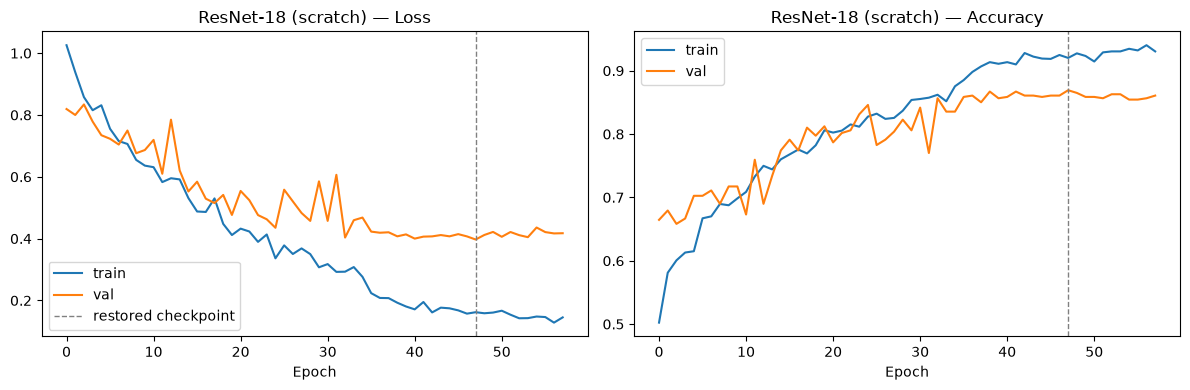

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.782


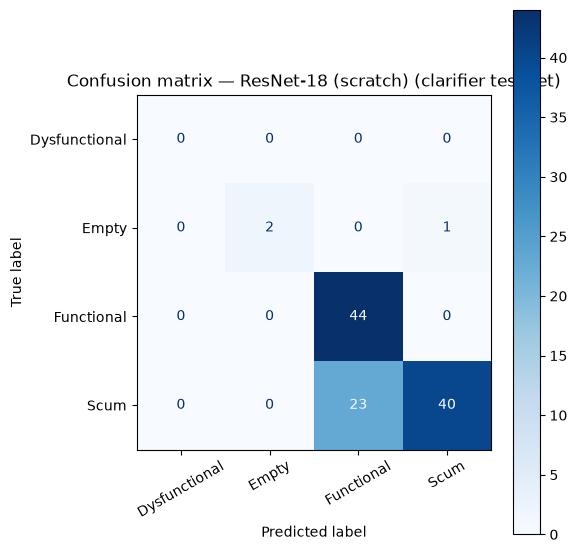

               precision    recall  f1-score   support

Dysfunctional      0.000     0.000     0.000         0
        Empty      1.000     0.667     0.800         3
   Functional      0.657     1.000     0.793        44
         Scum      0.976     0.635     0.769        63

     accuracy                          0.782       110
    macro avg      0.658     0.575     0.591       110
 weighted avg      0.849     0.782     0.779       110

  [warn] 'Dysfunctional' has 0 examples in this test set — AUC undefined, skipping.


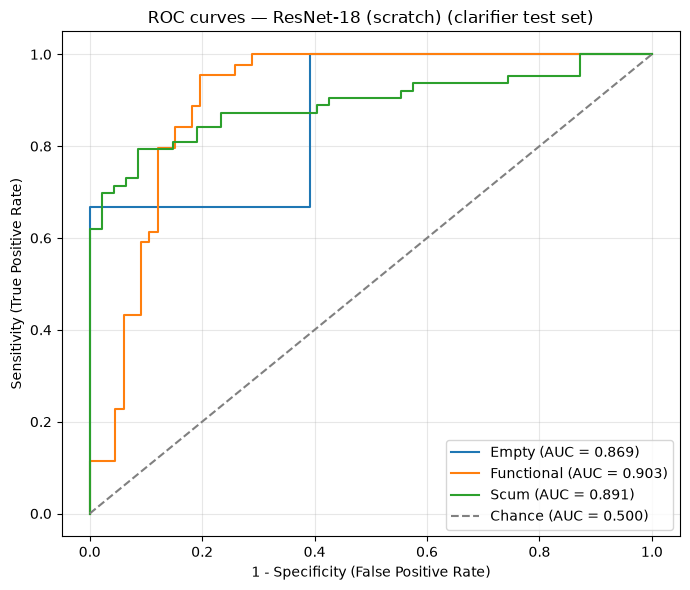

AUC (area under ROC curve) per class:
  Dysfunctional  : undefined (0 examples)
  Empty          : 0.869
  Functional     : 0.903
  Scum           : 0.891

Mean AUC (over 3/4 classes with test examples): 0.888


(np.float64(0.7818181818181819),
 {'Dysfunctional': nan,
  'Empty': 0.8691588785046729,
  'Functional': 0.9025482093663912,
  'Scum': 0.8909152313407631})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_Atlantis.pkl
Saved model weights to ../models/pad/clarifier_aug/clarifier_resnet18_scratch_Atlantis.pt
